# Experiment 200 · DINO and SimSiam health identifiability

**Complete** · Experiment 200 results saved · ETA 0h 00m 00s

Both learners use ViT-S/16 backbones initialized from the same pretrained coefficients. DINO retains its trained prototype head, EMA teacher, loss center, and two global plus two local views. SimSiam uses independently initialized repo batch-normalized projector and predictor heads and two training views. Every learner step processes the arriving image, 15/11/7 near-history images and 0/4/8 older images. Each model keeps its view count constant across replay arms.

Phase A uses three stochastic training seeds and a short 192-arrival A, B and return-A pilot. Histories start with the same 192 A images. The advancement rule requires at least two of three fixed-25% runs to preserve rank, variance and retrieval while the encoder changes. Training loss is logged for numerical diagnostics.

Phase B uses a longer A–B–A stream and four matched contexts per seed. It measures 256-arrival interventions with a common 256-arrival continuation, reading fixed monitor and test banks every 64 arrivals. The label-free objective gives equal weight to recent and historical retrieval. A reproducible two-point action interaction, a two-point benefit, and at least two-thirds informative draw-pair rank agreement are required to advance.

Initial branches use 12 development checkpoints and two draws per model. Successful models grow to 24 checkpoints and five draws for Phase C. Prediction uncertainty is clustered by model seed. Stage D uses exact 25% historical exposure and external probes. Task labels are kept out of fit, feature selection and policy decisions.

Pilot runs saved · 18. Counterfactual cases · 0. Prospective runs · 0.

## A · Fixed-policy pilots

| Model | Replay | Runs | Recent retrieval | Historical retrieval | RankMe | Variance | Pair similarity | Drift | Training s |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
 | DINO | 0% | 3 | 0.9780 | 0.9919 | 6.7877 | 0.8209 | 0.9575 | 0.3649 | 315.5 | 
 | DINO | 25% | 3 | 1.0000 | 1.0000 | 10.1159 | 2.2161 | 0.8940 | 0.2206 | 317.3 | 
 | DINO | 50% | 3 | 1.0000 | 1.0000 | 10.8121 | 2.6368 | 0.8759 | 0.1932 | 314.9 | 
 | SimSiam | 0% | 3 | 0.3634 | 0.3507 | 1.5524 | 0.1245 | 0.9938 | 0.9717 | 46.8 | 
 | SimSiam | 25% | 3 | 0.3854 | 0.4317 | 1.6427 | 0.1656 | 0.9916 | 0.9786 | 47.2 | 
 | SimSiam | 50% | 3 | 0.5706 | 0.5741 | 1.8989 | 0.2669 | 0.9862 | 0.9887 | 47.4 | 

| Model | Gate | Decision | Diagnostic |
| --- | --- | --- | --- |
 | DINO | pilot | stop | 0/3 seeds | 
 | SimSiam | pilot | stop | 0/3 seeds | 

## External downstream probes

| Model | Stage | Policy | Pairs | scene | weather | lighting | pedestrian |
| --- | --- | --- | --- | --- | --- | --- | --- |
 | DINO | pilot | 25% | 3 | 60.99% | 66.56% | 98.74% | 61.15% | 
 | SimSiam | pilot | 25% | 3 | 47.35% | 50.41% | 96.86% | 60.21% | 



In [ ]:
# Run this cell to watch the background worker. Interrupt it to stop watching.
from IPython.display import Image, Markdown, clear_output, display
from pathlib import Path
import base64, json, time

run = Path('C:\\CAFL-E\\analysis\\2026-11-09-one-step-mpc\\o3-joint-health')
while True:
    try:
        status = json.loads((run / 'status.json').read_text(encoding='utf-8'))
        cells = json.loads((run / 'progress.ipynb').read_text(encoding='utf-8'))['cells']
    except (FileNotFoundError, PermissionError):
        time.sleep(1)
        continue
    clear_output(wait=True)
    for cell in cells:
        if cell['cell_type'] == 'markdown':
            display(Markdown(''.join(cell['source'])))
        for output in cell.get('outputs', []):
            if png := output.get('data', {}).get('image/png'):
                display(Image(data=base64.b64decode(png)))
    if status['state'] in ('complete', 'stopped', 'failed'):
        break
    time.sleep(10)


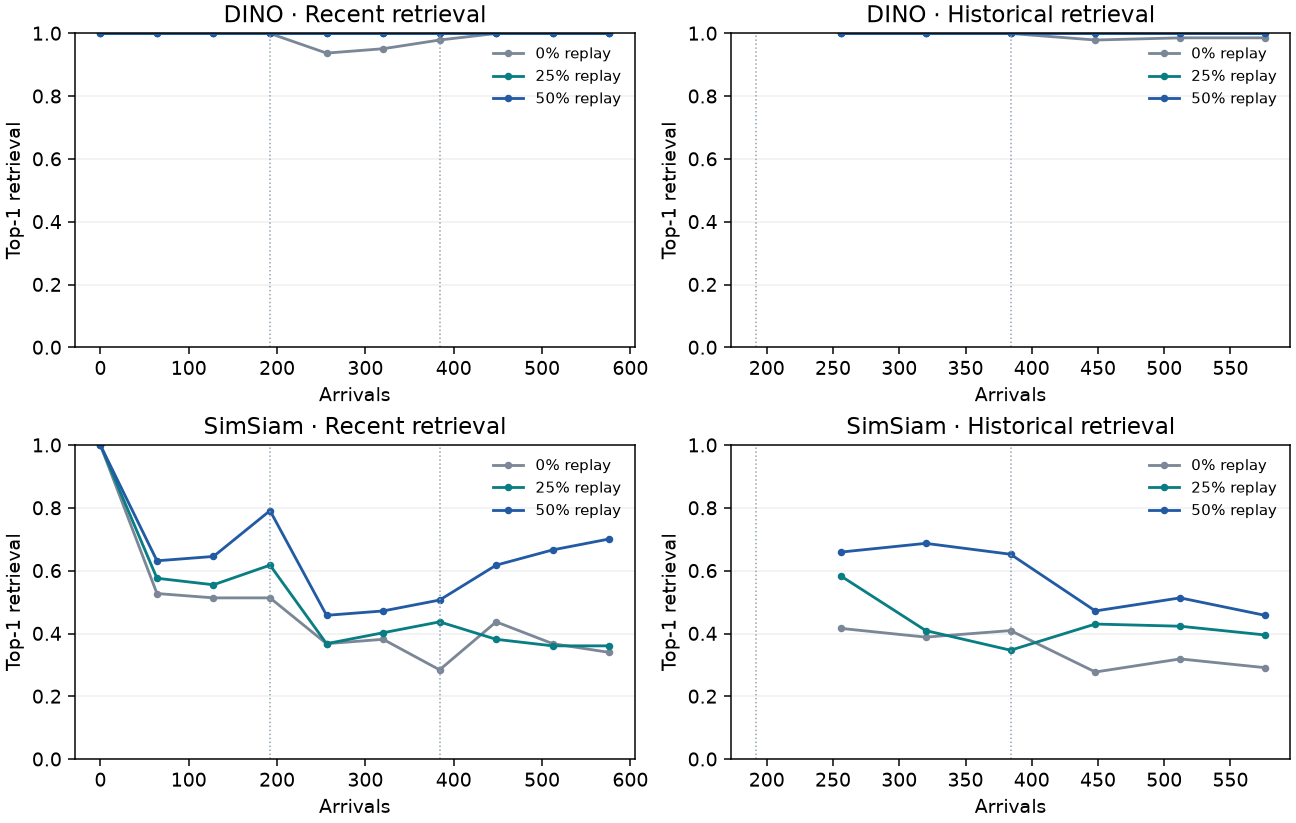